# Smart Traffic Management System

Hourly traffic volume prediction, geospatial congestion visualization, and REST inference for **I-94 Westbound (Minneapolis-St. Paul, MN)** using **XGBoost**, **Folium**, **ipywidgets**, and **FastAPI**.

### Pipeline Overview
1. **Data Cleaning, EDA & Feature Engineering** - Deduplication, timestamp parsing, rush-hour analysis, weather encoding, and export to `dataset/traffic_data_cleaned.csv`.
2. **Model Training & Serialization** - `XGBRegressor` training (`80/20` split), evaluation ($R^2 = 96.54\%$, $\text{RMSE} = 372$ vehicles, $\text{MAE} = 218$ vehicles), and model export to `model/traffic_xgboost_model.pkl`.
3. **Interactive Congestion Dashboard** - `ipywidgets` control panel with Folium marker & heatmap rendering exported to `visualizations/traffic_map_view.html`.
4. **FastAPI Prediction Service** - Typed `POST /api/predict-traffic` REST endpoint.

## 1. Data Preparation & Exploratory Data Analysis

### 1.1 Dataset Overview
- **Source:** [UCI Metro Interstate Traffic Volume](https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume) (`dataset/Metro_Interstate_Traffic_Volume.csv`)
- **Scope:** `48,204` hourly records (2012-2018) containing traffic volume, temperature (`temp`), precipitation (`rain_1h`, `snow_1h`), cloud coverage (`clouds_all`), weather category (`weather_main`), and holiday flags (`holiday`).

### 1.2 Environment Setup & Data Loading

In [1]:
# pip install pandas numpy seaborn matplotlib xgboost scikit-learn folium ipywidgets joblib

import os
from typing import TypedDict

import folium
import ipywidgets as widgets
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from folium.plugins import HeatMap
from IPython.display import HTML, IFrame, clear_output, display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 1. LOAD DATA
df: pd.DataFrame = pd.read_csv(
    'dataset/Metro_Interstate_Traffic_Volume.csv',
    keep_default_na=False,
)

ShapeString = f"Original Dataset Shape: {df.shape}"

print("=" * len(ShapeString))
print(ShapeString)
print("=" * len(ShapeString))

Original Dataset Shape: (48204, 9)


### 1.3 Deduplication & Timestamp Parsing
Remove duplicate records and parse `date_time` into `datetime64` for downstream feature extraction.

In [2]:
# SECTION A: EXPLORATORY DATA ANALYSIS (EDA)
# Check for duplicates (Common in this specific dataset)

DuplicatesFoundString = f"Duplicates found: {df.duplicated().sum()}"

print("=" * len(DuplicatesFoundString))
print(DuplicatesFoundString)
print("=" * len(DuplicatesFoundString))

df = df.drop_duplicates().copy()

# Convert date_time to proper datetime objects
df['date_time'] = pd.to_datetime(df['date_time'], format='%Y-%m-%d %H:%M:%S')

Duplicates found: 17


### 1.4 Traffic Volume Distribution
Inspect the target distribution (`traffic_volume`) across low-volume and peak-congestion regimes.

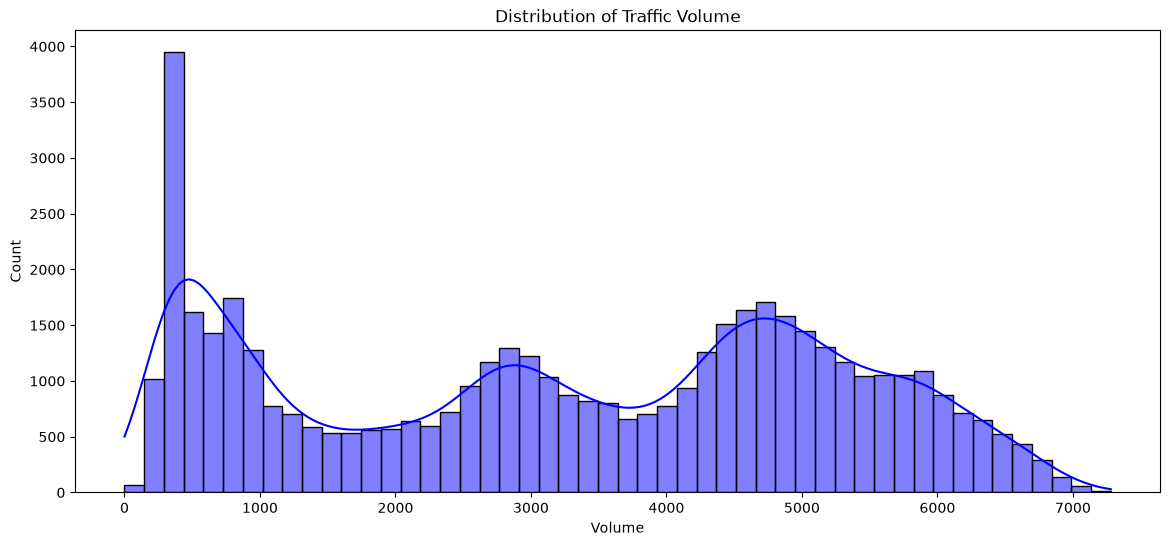

In [3]:
# Plot 1: Traffic Volume Distribution
plt.figure(figsize=(14, 6))
sns.histplot(df['traffic_volume'], bins=50, kde=True, color='blue') # type: ignore
plt.title('Distribution of Traffic Volume')
plt.xlabel('Volume')
plt.show()


### 1.5 Hourly Congestion Pattern
Examine hourly traffic cycles (`0-23`) to verify morning and evening rush-hour peaks.

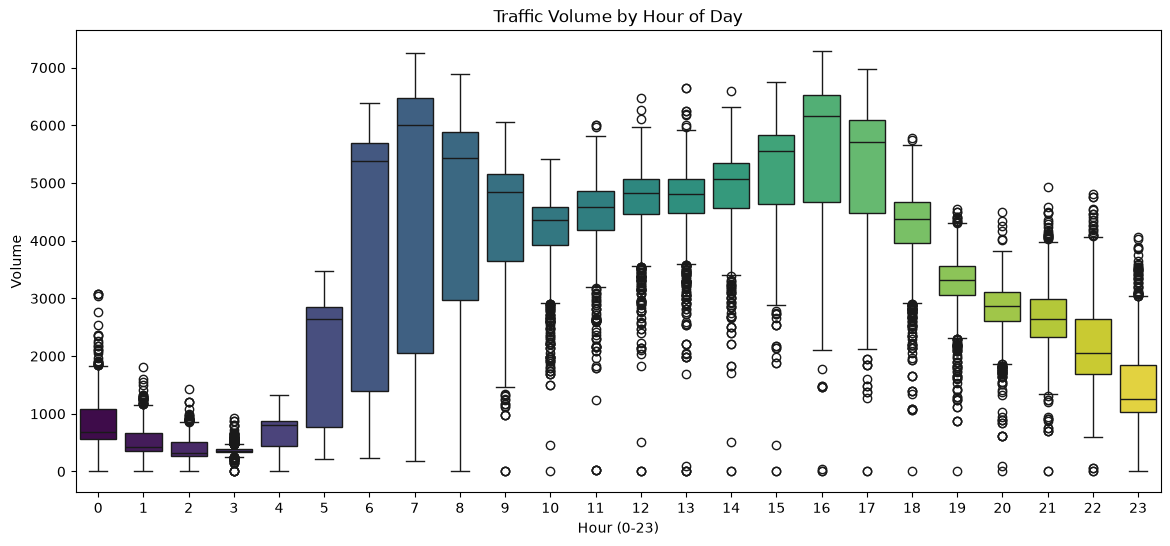

In [4]:
# Plot 2: Traffic vs Hour of Day (The "Rush Hour" Pattern)
# We extract hour temporarily for visualization
df['temp_hour'] = df['date_time'].dt.hour # type: ignore

plt.figure(figsize=(14, 6))

# FIXED LINE: Added hue='temp_hour' and legend=False
sns.boxplot(
    x='temp_hour',
    y='traffic_volume',
    data=df,
    palette='viridis',
    hue='temp_hour',
    legend=False,
)

plt.title('Traffic Volume by Hour of Day')
plt.xlabel('Hour (0-23)')
plt.ylabel('Volume')
plt.show()

df = df.drop(columns=['temp_hour'])  # Clean up

### 1.6 Temporal, Contextual & Weather Feature Engineering
Extract numeric time features (`hour`, `month`, `day_of_week`, `year`), binary flags (`is_weekend`, `is_holiday`), and `LabelEncoder` integer codes (`weather_code`).

In [5]:
# SECTION B: DATA PRE-PROCESSING & FEATURE ENGINEERING
# 1. Time Features (Crucial for Traffic Prediction)
# The model can't read dates, so we break them into numbers.

df['hour'] = df['date_time'].dt.hour  # type: ignore
df['month'] = df['date_time'].dt.month  # type: ignore
df['day_of_week'] = df['date_time'].dt.day_of_week  # type: ignore # 0=Monday, 6=Sunday
df['year'] = df['date_time'].dt.year  # type: ignore

# 2. Engineer "Is_Weekend" Feature
# Traffic patterns differ massively on weekends.

df['is_weekend'] = df['day_of_week'].apply(lambda x: 1 if x >= 5 else 0)

# 3. Categorical Encoding (Weather & Holidays)
# The 'holiday' column is mostly "None". We make it binary: Is it a holiday? Yes/No.

df['is_holiday'] = df['holiday'].apply(lambda x: 0 if x == 'None' else 1)

# Label Encode 'weather_main' (Rain, Clouds, Clear, etc.)
# We drop 'weather_description' as it's too specific/redundant.
le = LabelEncoder()
df['weather_code'] = le.fit_transform(df['weather_main'])

# Save the mapping so we know what 0, 1, 2 mean later
weather_mapping = dict(zip(le.classes_, le.transform(le.classes_))) # type: ignore
print("Weather Mapping Created:")
for key, value in weather_mapping.items():
    print(f"{key} : {value}")

Weather Mapping Created:
Clear : 0
Clouds : 1
Drizzle : 2
Fog : 3
Haze : 4
Mist : 5
Rain : 6
Smoke : 7
Snow : 8
Squall : 9
Thunderstorm : 10


### 1.7 Feature Selection
Drop raw string and timestamp columns (`holiday`, `weather_main`, `weather_description`, `date_time`) replaced by engineered numeric features.

In [6]:
# 4. Drop Unusable Columns
# - 'holiday': Replaced by is_holiday
# - 'weather_main': Replaced by weather_code
# - 'weather_description': Too noisy
# - 'date_time': We extracted the useful parts

Columns_To_Be_Dropped = ['holiday', 'weather_main', 'weather_description', 'date_time']
df_clean = df.drop(columns=Columns_To_Be_Dropped)


### 1.8 Feature Verification
Verify the encoded dataframe using deterministic weather codes (`Clear = 0`, `Clouds = 1`, `Rain = 6`, `Snow = 8`, `Thunderstorm = 10`, etc.) shared across the dashboard and FastAPI endpoint.

In [7]:
# SECTION C: FINAL CHECK
df_clean.head()


,temp,rain_1h,snow_1h,clouds_all,traffic_volume,hour,month,day_of_week,year,is_weekend,is_holiday,weather_code
0,288.28,0.0,0.0,40,5545,9,10,1,2012,0,0,1
1,289.36,0.0,0.0,75,4516,10,10,1,2012,0,0,1
2,289.58,0.0,0.0,90,4767,11,10,1,2012,0,0,1
3,290.13,0.0,0.0,90,5026,12,10,1,2012,0,0,1
4,291.14,0.0,0.0,75,4918,13,10,1,2012,0,0,1


### 1.9 Dataset Summary & Export
Inspect schema types and save the cleaned feature table to `dataset/traffic_data_cleaned.csv`.

In [8]:
df_clean.info()


<class 'pandas.DataFrame'>
Index: 48187 entries, 0 to 48203
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   temp            48187 non-null  float64
 1   rain_1h         48187 non-null  float64
 2   snow_1h         48187 non-null  float64
 3   clouds_all      48187 non-null  int64  
 4   traffic_volume  48187 non-null  int64  
 5   hour            48187 non-null  int32  
 6   month           48187 non-null  int32  
 7   day_of_week     48187 non-null  int32  
 8   year            48187 non-null  int32  
 9   is_weekend      48187 non-null  int64  
 10  is_holiday      48187 non-null  int64  
 11  weather_code    48187 non-null  int64  
dtypes: float64(3), int32(4), int64(5)
memory usage: 4.0 MB


In [9]:
# Save to new CSV for Training
os.makedirs('dataset', exist_ok=True)
df_clean.to_csv('dataset/traffic_data_cleaned.csv', index=False)
print("Success! Cleaned dataset saved as 'dataset/traffic_data_cleaned.csv'")


Success! Cleaned dataset saved as 'dataset/traffic_data_cleaned.csv'


## 2. Model Training & Evaluation

### 2.1 Feature/Target Split
Load `dataset/traffic_data_cleaned.csv` and separate `traffic_volume` (`Y`) from the 11 input features (`X`).

In [10]:
# Load Cleaned Data
df = pd.read_csv('dataset/traffic_data_cleaned.csv')
X = df.drop(columns=['traffic_volume'])
Y = df['traffic_volume']

### 2.2 Train/Test Split (`80/20`)

In [11]:
# Split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

### 2.3 XGBoost Regressor Training & Evaluation
Train `XGBRegressor(objective='reg:squarederror', n_estimators=1000, learning_rate=0.05)` and evaluate using $R^2$, RMSE, and MAE.

In [12]:
# Train XGBoost
model = xgb.XGBRegressor(
    objective='reg:squarederror',
    n_estimators=1000,
    learning_rate=0.05,
    random_state=42,
)
model.fit(X_train, Y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [13]:
# Model evaluation

# Predict on Test Set
predictions = model.predict(X_test)

# Calculate Metrics
MEAN_SQUARED_ERROR = mean_squared_error(Y_test, predictions)
ROOT_MEAN_SQUARED_ERROR = np.sqrt(MEAN_SQUARED_ERROR)
R2 = r2_score(Y_test, predictions)
MEAN_ABSOLUTE_ERROR = mean_absolute_error(Y_test, predictions)

print("=" * 30)
print("MODEL PERFORMANCE REPORT")
print("=" * 30)
print(
    f"R2 Score (Accuracy): {(R2 * 100):.2f}% "
    "(Target: at least 85% accuracy for this regression task)"
)
print(f"RMSE (Error):             {ROOT_MEAN_SQUARED_ERROR:.0f} vehicles")
print(f"MAE (Avg Deviation):      {MEAN_ABSOLUTE_ERROR:.0f} vehicles")

MODEL PERFORMANCE REPORT
R2 Score (Accuracy): 96.54% (Target: at least 85% accuracy for this regression task)
RMSE (Error):             372 vehicles
MAE (Avg Deviation):      218 vehicles


### 2.4 Model Serialization
Export the trained model to `model/traffic_xgboost_model.pkl` with `joblib`.

In [14]:
# Save Model
os.makedirs('model', exist_ok=True)
joblib.dump(model, 'model/traffic_xgboost_model.pkl')
print("Model saved successfully!")


Model saved successfully!


## 3. Interactive Congestion Dashboard

### 3.1 Corridor Monitoring Locations & Inference Logic
Simulate traffic volume across three I-94 Westbound nodes (`Huron Blvd`, `I-35W Interchange`, `Lowry Hill Tunnel`) and classify congestion into zones:
- **Green:** `< 1,000` vehicles (Free Flow)
- **Orange:** `1,000-3,999` vehicles (Moderate)
- **Red:** `>= 4,000` vehicles (Heavy Congestion)

In [15]:
# 1. LOAD THE TRAINED MODEL
MODEL = joblib.load('model/traffic_xgboost_model.pkl')


class LocationConfig(TypedDict):
    coords: list[float]
    offset: int


# 2. DEFINE HIGHWAY MONITORING LOCATIONS (I-94 Westbound Minneapolis)
MONITORING_LOCATIONS: dict[str, LocationConfig] = {
    "Node A (Huron Blvd)": {"coords": [44.96773, -93.22262], "offset": 0},
    "Node B (I-35W Interchange)": {"coords": [44.96594, -93.25644], "offset": 200},  # Slightly busier
    "Node C (Lowry Hill Tunnel)": {"coords": [44.96993, -93.28764], "offset": 500},  # Bottleneck (Highest traffic)
}

In [16]:
# 3. HELPER: GET CONGESTION COLOR
def GetZoneColor(Volume: float) -> str:
    if Volume < 1000:
        return 'green'
    elif Volume < 4000:
        return 'orange'
    else:
        return 'red'

In [17]:
# 4. SIMULATION FUNCTION
# Matches LabelEncoder weather codes: Clear=0, Clouds=1, Rain=6, Snow=8, Thunderstorm=10
WEATHER_PRESETS: dict[int, dict[str, float | int]] = {
    0: {"temp": 285.0, "rain_1h": 0.0, "snow_1h": 0.0, "clouds_all": 10},   # Clear
    1: {"temp": 282.0, "rain_1h": 0.0, "snow_1h": 0.0, "clouds_all": 85},   # Clouds
    6: {"temp": 278.0, "rain_1h": 5.0, "snow_1h": 0.0, "clouds_all": 90},   # Rain
    8: {"temp": 269.0, "rain_1h": 0.0, "snow_1h": 3.0, "clouds_all": 95},   # Snow
    10: {"temp": 280.0, "rain_1h": 10.0, "snow_1h": 0.0, "clouds_all": 100}, # Thunderstorm
}


class ZonePrediction(TypedDict):
    label: str
    coords: list[float]
    volume: int
    color: str


def PredictTrafficCongestion(
    Hour: int,
    DayOfWeek: int,
    WeatherCode: int,
    IsWeekend: int,
) -> list[ZonePrediction]:
    Predictions: list[ZonePrediction] = []
    preset = WEATHER_PRESETS.get(WeatherCode, WEATHER_PRESETS[0])

    for Name, Data in MONITORING_LOCATIONS.items():
        InputData = pd.DataFrame([{
            'temp': preset['temp'],
            'rain_1h': preset['rain_1h'],
            'snow_1h': preset['snow_1h'],
            'clouds_all': preset['clouds_all'],
            'hour': Hour,
            'month': 10,
            'day_of_week': DayOfWeek,
            'year': 2024,
            'is_weekend': IsWeekend,
            'is_holiday': 0,
            'weather_code': WeatherCode,
        }])

        PredictedVolume = float(MODEL.predict(InputData)[0])
        Volume = max(0.0, PredictedVolume + Data['offset'])

        Predictions.append({
            'label': Name,
            'coords': Data['coords'],
            'volume': int(Volume),
            'color': GetZoneColor(Volume),
        })

    return Predictions

### 3.2 Interactive Widget Controls

In [18]:
# 5. DASHBOARD WIDGETS & STYLING
ControlLayout = widgets.Layout(width='300px', margin='10px 10px 10px 0px')
ContainerLayout = widgets.Layout(
    border='1px solid #ddd',
    padding='20px',
    margin='20px 0px',
    border_radius='10px',
    width='100%'
)

HeaderHTML = widgets.HTML(
    value="""
    <div style="background-color: #2c3e50; padding: 15px; border-radius: 5px; color: white;">
        <h2 style="margin:0; font-family: sans-serif;">🚦 Smart Traffic Congestion Monitor</h2>
        <p style="margin:5px 0 0 0; font-family: sans-serif; opacity: 0.8;">
            Simulate traffic conditions on I-94 Minneapolis based on Time and Weather.
        </p>
    </div>
    """
)

HourSlider = widgets.IntSlider(
    min=0, max=23, step=1, value=12,
    description='⏱ Hour:',
    style={'description_width': '80px'},
    layout=ControlLayout
)

DayDropdown = widgets.Dropdown(
    options=[
        ('Monday', 0),
        ('Tuesday', 1),
        ('Wednesday', 2),
        ('Thursday', 3),
        ('Friday', 4),
        ('Saturday', 5),
        ('Sunday', 6)
    ],
    value=0,
    description='📅 Day:',
    style={'description_width': '80px'},
    layout=ControlLayout
)

WeatherDropdown = widgets.Dropdown(
    options=[
        ('Clear', 0),
        ('Clouds', 1),
        ('Rain', 6),
        ('Snow', 8),
        ('Thunderstorm', 10)
    ],
    value=0,
    description='☁ Weather:',
    style={'description_width': '80px'},
    layout=ControlLayout
)

DashboardUpdateButton = widgets.Button(
    description=" Generate Prediction",
    button_style='primary',
    icon='play',
    layout=widgets.Layout(width='98%', margin='20px 0px')
)

OutputMap = widgets.Output()


### 3.3 Folium Map & Heatmap Rendering
Render color-coded markers and a traffic intensity heatmap saved to `visualizations/traffic_map_view.html`.

In [19]:
# 6. UPDATE FUNCTION
def UpdateDashboard(b: object | None) -> None:
    with OutputMap:
        clear_output()

        Hour = int(HourSlider.value)
        Day = int(DayDropdown.value)
        Weather = int(WeatherDropdown.value)
        IsWeekend = 1 if Day >= 5 else 0

        Results = PredictTrafficCongestion(Hour, Day, Weather, IsWeekend)

        CityMap = folium.Map(
            location=[44.962, -93.25],
            zoom_start=13,
            tiles='Esri.WorldTopoMap',
        )

        display(HTML(f"""
            <div style="background-color: #ecf0f1; padding: 10px; border-left: 5px solid #3498db; margin-bottom: 10px;">
                <strong>Simulation Report:</strong> Prediction for {Hour}:00 hours.
            </div>
        """))

        HeatMapData = []
        for r in Results:
            popup_html = (
                f"<b>{r['label']}</b><br>"
                f"Volume: {r['volume']}<br>"
                f"Status: {r['color'].upper()}"
            )
            folium.Marker(
                location=r['coords'],
                popup=folium.Popup(popup_html, max_width=280),
                icon=folium.Icon(color=r['color'], icon='car', prefix='fa'),
            ).add_to(CityMap)

            Intensity = r['volume'] / 6000
            HeatMapData.append([r['coords'][0], r['coords'][1], Intensity])
            print(f"{r['label']}: {r['volume']} vehicles ({r['color'].upper()})")

        HeatMap(HeatMapData, radius=30, blur=20, max_zoom=1).add_to(CityMap)

        os.makedirs('visualizations', exist_ok=True)
        MapFileName = 'visualizations/traffic_map_view.html'
        CityMap.save(MapFileName)
        display(IFrame(src=MapFileName, width='100%', height='500px'))


DashboardUpdateButton.on_click(UpdateDashboard)

# 7. DISPLAY LAYOUT
ControlPanel = widgets.HBox(
    [HourSlider, DayDropdown, WeatherDropdown],
    layout=widgets.Layout(flex_flow='row wrap', align_items='center'),
)

UI = widgets.VBox([
    HeaderHTML,
    widgets.VBox([
        ControlPanel,
        DashboardUpdateButton,
    ], layout=ContainerLayout),
    OutputMap,
])

UpdateDashboard(None)
display(UI)

Node A (Huron Blvd): 4840 vehicles (RED)
Node B (I-35W Interchange): 5040 vehicles (RED)
Node C (Lowry Hill Tunnel): 5340 vehicles (RED)


## 4. FastAPI Prediction Service (`POST /api/predict-traffic`)

Expose `model/traffic_xgboost_model.pkl` as a typed FastAPI REST endpoint (`TrafficPredictionRequest`) returning predicted volume, congestion level (`green`, `orange`, `red`), and decoded weather label. Set `RUN_API_SERVER = True` to launch `uvicorn`.

In [20]:
# pip install fastapi pydantic uvicorn

from pathlib import Path

import joblib
import pandas as pd
from fastapi import FastAPI
from pydantic import BaseModel, Field

app = FastAPI(title="Smart Traffic Volume Prediction API")

MODEL_PATH = Path("model/traffic_xgboost_model.pkl")
api_model = joblib.load(MODEL_PATH)

FEATURE_COLUMNS = [
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "hour",
    "month",
    "day_of_week",
    "year",
    "is_weekend",
    "is_holiday",
    "weather_code",
]

WEATHER_CODE_MAP = {
    0: "Clear",
    1: "Clouds",
    2: "Drizzle",
    3: "Fog",
    4: "Haze",
    5: "Mist",
    6: "Rain",
    7: "Smoke",
    8: "Snow",
    9: "Squall",
    10: "Thunderstorm",
}


class TrafficPredictionRequest(BaseModel):
    hour: int = Field(..., ge=0, le=23)
    day_of_week: int = Field(..., ge=0, le=6)
    month: int = Field(10, ge=1, le=12)
    year: int = Field(2024, ge=2012)
    weather_code: int = Field(0, ge=0, le=10)
    temp: float = 285.0
    rain_1h: float = 0.0
    snow_1h: float = 0.0
    clouds_all: int = Field(40, ge=0, le=100)
    is_holiday: int = Field(0, ge=0, le=1)


@app.post("/api/predict-traffic")
async def predict_traffic(request: TrafficPredictionRequest) -> dict[str, int | str]:
    is_weekend = 1 if request.day_of_week >= 5 else 0
    input_df = pd.DataFrame(
        [
            {
                "temp": request.temp,
                "rain_1h": request.rain_1h,
                "snow_1h": request.snow_1h,
                "clouds_all": request.clouds_all,
                "hour": request.hour,
                "month": request.month,
                "day_of_week": request.day_of_week,
                "year": request.year,
                "is_weekend": is_weekend,
                "is_holiday": request.is_holiday,
                "weather_code": request.weather_code,
            }
        ],
        columns=FEATURE_COLUMNS,
    )
    predicted_volume = max(0, int(api_model.predict(input_df)[0]))
    return {
        "predicted_traffic_volume": predicted_volume,
        "congestion_level": GetZoneColor(predicted_volume),
        "weather": WEATHER_CODE_MAP.get(request.weather_code, "Unknown"),
    }


RUN_API_SERVER = False
if RUN_API_SERVER:
    import uvicorn

    uvicorn.run(app, host="0.0.0.0", port=8000)